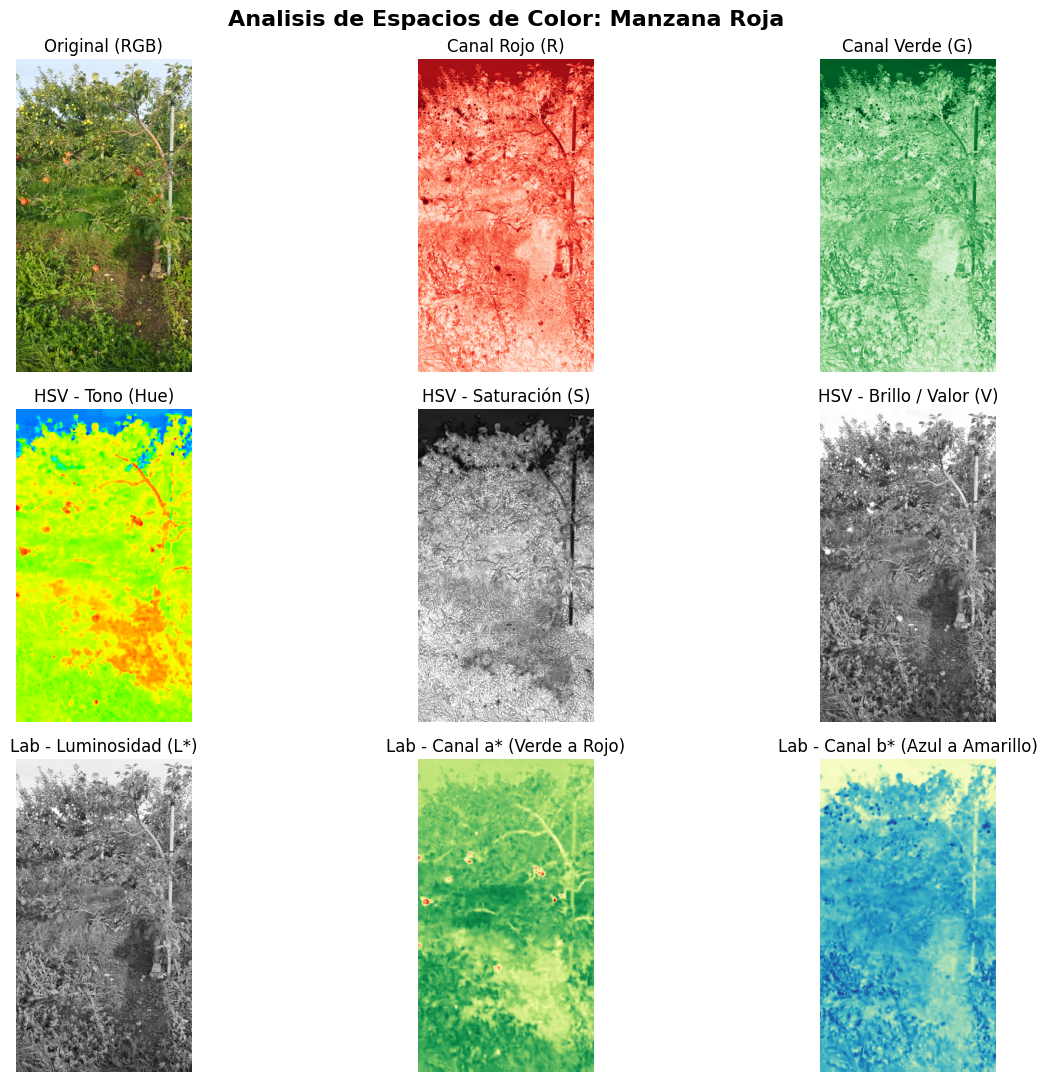

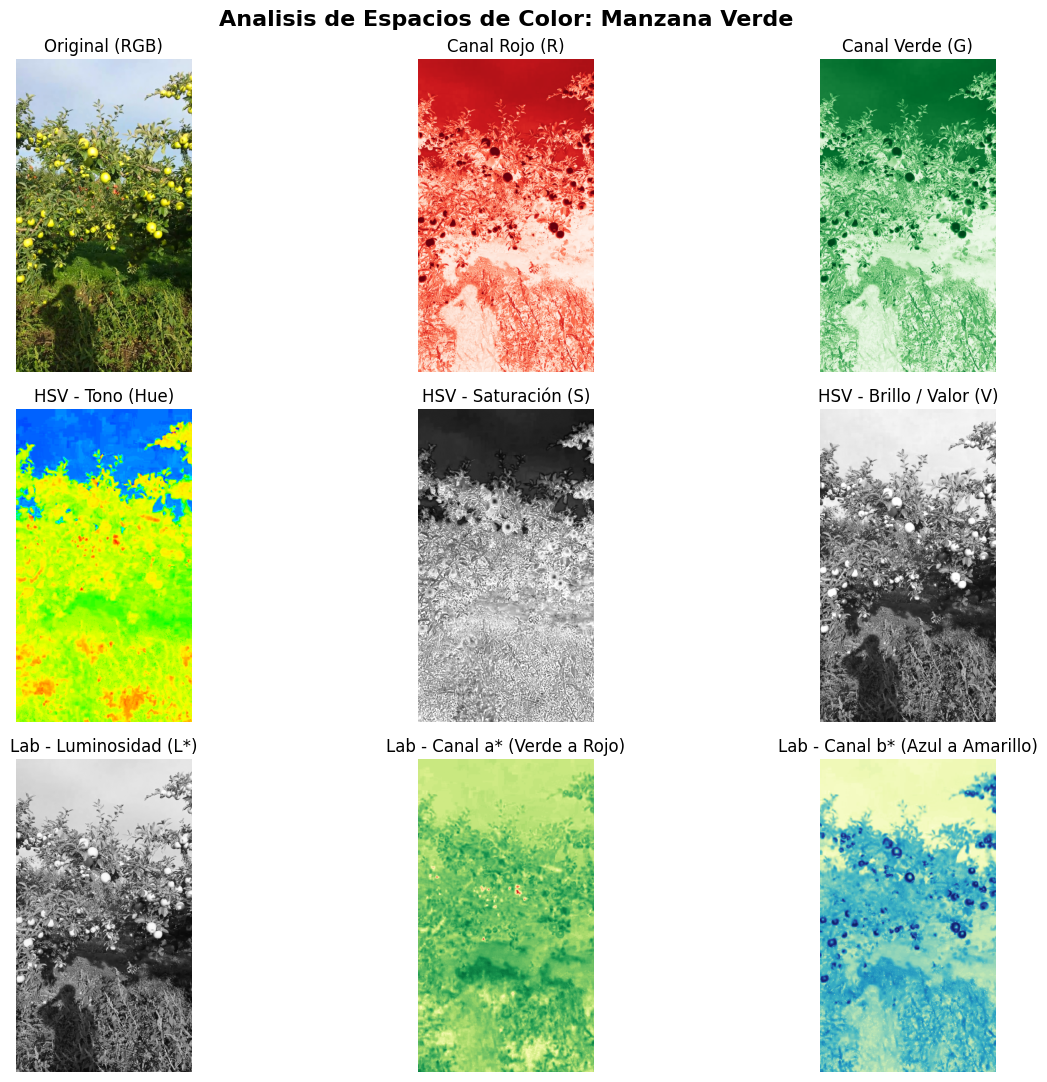

In [8]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def inspeccionar_espacios_color(image_path, tipo_manzana="Desconocida"):
    # 1. Cargar la imagen en formato BGR (estándar de OpenCV)
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"Error: No se pudo cargar la imagen en la ruta '{image_path}'")
        return

    # Convertir BGR a RGB para visualización en Matplotlib
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 2. Conversión a espacios de color de interés
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

    # Descomponer canales
    h, s, v = cv2.split(img_hsv)
    l, a, b = cv2.split(img_lab)

    # 3. Crear matriz de figuras para comparar
    fig, axes = plt.subplots(3, 3, figsize=(14, 11))
    fig.suptitle(f'Analisis de Espacios de Color: {tipo_manzana}', fontsize=16, fontweight='bold')

    # Fila 1: RGB Original y canales R, G
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("Original (RGB)")
    axes[0, 1].imshow(img_rgb[:, :, 0], cmap='Reds')
    axes[0, 1].set_title("Canal Rojo (R)")
    axes[0, 2].imshow(img_rgb[:, :, 1], cmap='Greens')
    axes[0, 2].set_title("Canal Verde (G)")

    # Fila 2: Espacio HSV (Tono, Saturación, Valor)
    axes[1, 0].imshow(h, cmap='hsv')
    axes[1, 0].set_title("HSV - Tono (Hue)")
    axes[1, 1].imshow(s, cmap='gray')
    axes[1, 1].set_title("HSV - Saturación (S)")
    axes[1, 2].imshow(v, cmap='gray')
    axes[1, 2].set_title("HSV - Brillo / Valor (V)")

    # Fila 3: Espacio Lab (Luminosidad, a*, b*)
    axes[2, 0].imshow(l, cmap='gray')
    axes[2, 0].set_title("Lab - Luminosidad (L*)")
    axes[2, 1].imshow(a, cmap='RdYlGn_r')  # Verde <-> Rojo
    axes[2, 1].set_title("Lab - Canal a* (Verde a Rojo)")
    axes[2, 2].imshow(b, cmap='YlGnBu')  # Azul <-> Amarillo
    axes[2, 2].set_title("Lab - Canal b* (Azul a Amarillo)")

    for ax in axes.ravel():
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Ejemplo de uso con una imagen de tu dataset:
inspeccionar_espacios_color(r'dataset_manzanas/imagenes/img_079.png', 'Manzana Roja')
inspeccionar_espacios_color(r'dataset_manzanas/imagenes/img_001.png', 'Manzana Verde')


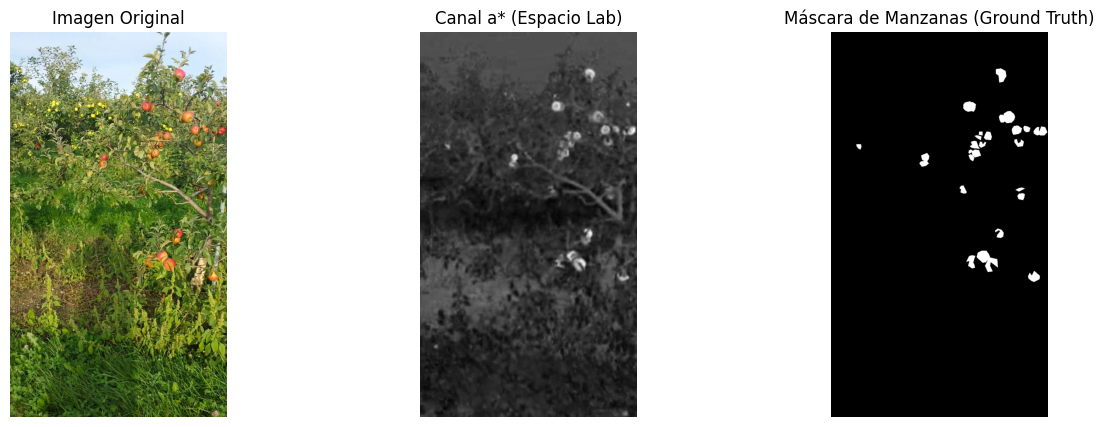

In [ ]:
def mascara_manzanas_lab(img_bgr, umbral_min=140, umbral_max=255):
    # Convertir a Lab
    img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(img_lab)
    
    # Umbralizar el canal a* (destaca píxeles rojizos)
    _, mascara_binaria = cv2.threshold(a, umbral_min, umbral_max, cv2.THRESH_BINARY)
    
    return a, mascara_binaria

a_channel, mascara = mascara_manzanas_lab(cv2.imread(r'dataset_manzanas/imagenes/img_094.png'))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(cv2.imread(r'dataset_manzanas/imagenes/img_094.png'), cv2.COLOR_BGR2RGB))
plt.title("Imagen Original")    
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(a_channel, cmap='gray')
plt.title("Canal a* (Espacio Lab)")
plt.axis('off')

mascara = cv2.imread(r'dataset_manzanas/mascaras/img_094.png', cv2.IMREAD_GRAYSCALE)
plt.subplot(1, 3, 3)
plt.imshow(mascara, cmap='gray')
plt.title("Máscara de Manzanas (Ground Truth)")
plt.axis('off')


plt.show()

In [32]:
def preprocesar_canal(img, img_id):
    # 1. Convertir a Lab
    img_lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    # 2. Selección del canal según ID de la imagen
    if img_id < 66:
        # Manzanas verdes: usamos canal b* (tienden a matiz amarillo/verde claro)
        canal = img_lab[:, :, 2]
    else:
        # Manzanas rojas: usamos canal a* (destaca el rojo)
        canal = img_lab[:, :, 1]
    
    # 3. Normalizar rango dinámico a 0-255
    canal_norm = cv2.normalize(canal, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    
    # 4. Realce de contraste adaptativo con CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    canal_clahe = clahe.apply(canal_norm)
    
    # 5. Suavizado bilateral para quitar ruido respetando los bordes de la fruta
    canal_procesado = cv2.bilateralFilter(canal_clahe, d=9, sigmaColor=75, sigmaSpace=75)
    
    return canal_procesado


ID de la imagen: ['img', '079.png']


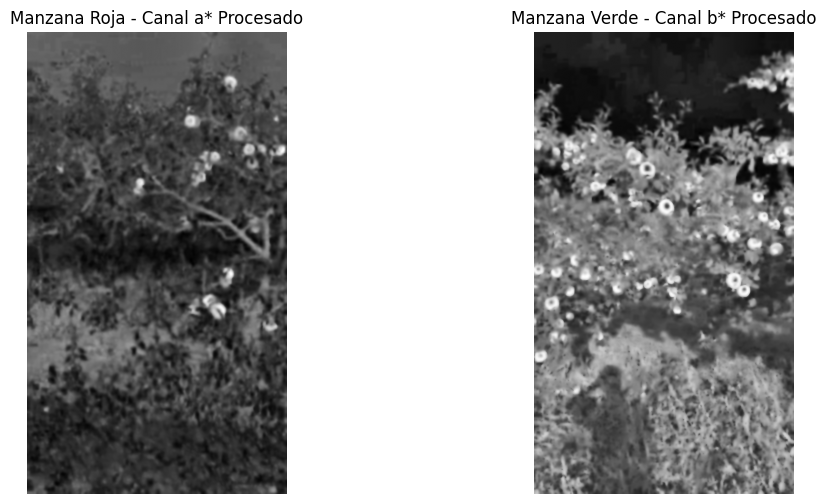

In [11]:
manzana_roja=preprocesar_canal(cv2.imread(r'dataset_manzanas/imagenes/img_094.png'), 94)
manzana_verde=preprocesar_canal(cv2.imread(r'dataset_manzanas/imagenes/img_001.png'), 1)


plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(manzana_roja, cmap='gray')
plt.title("Manzana Roja - Canal a* Procesado")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(manzana_verde, cmap='gray')
plt.title("Manzana Verde - Canal b* Procesado")
plt.axis('off')

plt.show()


In [12]:
import cv2
import numpy as np


class BinarizadorYLimpiador:
    """
    Bloque 2 del Pipeline: Binariza el canal preprocesado y aplica filtrado
    morfológico para obtener una máscara limpia de manzanas.
    """

    def __init__(self, kernel_size=7, metodo="otsu"):
        self.metodo = metodo
        # Elemento estructurante elíptico (mejor adaptación a formas circulares)
        self.kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (kernel_size, kernel_size)
        )

    def procesar(self, canal_preprocesado):
        # 1. Binarización
        if self.metodo == "otsu":
            _, mascara_raw = cv2.threshold(
                canal_preprocesado, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )
        elif self.metodo == "adaptativo":
            mascara_raw = cv2.adaptiveThreshold(
                canal_preprocesado,
                255,
                cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                cv2.THRESH_BINARY,
                blockSize=31,
                C=2,
            )
        else:
            raise ValueError(
                f"Método no válido: '{self.metodo}'. Usa 'otsu' o 'adaptativo'."
            )

        # 2. Limpieza Morfológica
        # Paso A: Apertura para eliminar pequeñas motas y ruido en hojas
        mascara_apertura = cv2.morphologyEx(mascara_raw, cv2.MORPH_OPEN, self.kernel)

        # Paso B: Cierre para rellenar huecos de brillo dentro de las manzanas
        mascara_limpia = cv2.morphologyEx(
            mascara_apertura, cv2.MORPH_CLOSE, self.kernel
        )

        return mascara_limpia


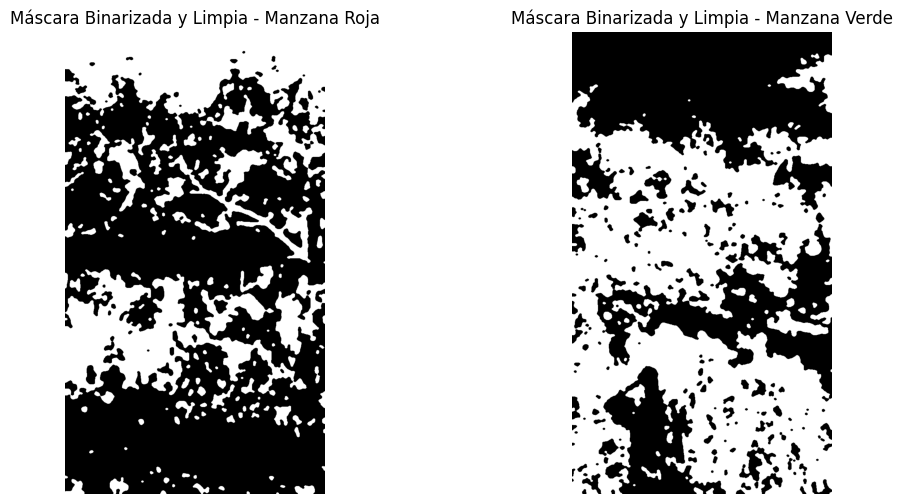

In [13]:
binarizador = BinarizadorYLimpiador(kernel_size=7, metodo="otsu")

# Procesar la manzana roja
mascara_roja = binarizador.procesar(manzana_roja)

# Procesar la manzana verde
mascara_verde = binarizador.procesar(manzana_verde)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)

plt.imshow(mascara_roja, cmap='gray')
plt.title("Máscara Binarizada y Limpia - Manzana Roja")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mascara_verde, cmap='gray')
plt.title("Máscara Binarizada y Limpia - Manzana Verde")
plt.axis('off')

plt.show()

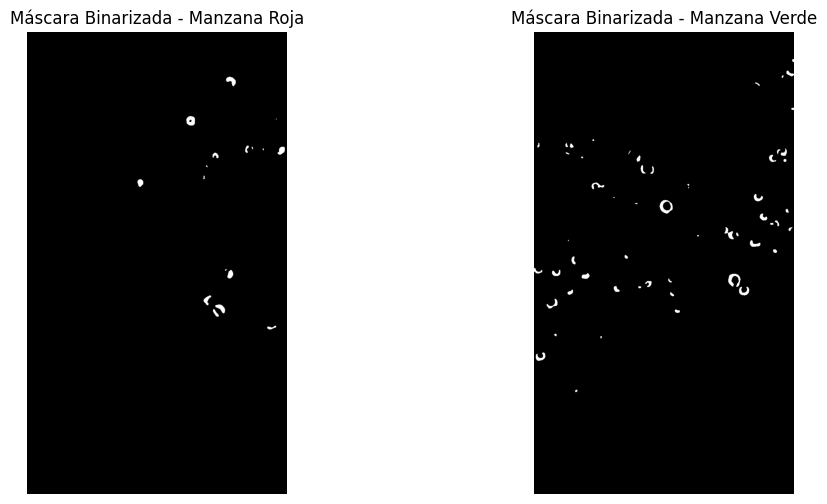

In [14]:
_,mascara_roja = cv2.threshold(manzana_roja, 190, 255, cv2.THRESH_BINARY)

_,mascara_verde = cv2.threshold(manzana_verde, 230, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(mascara_roja, cmap='gray')
plt.title("Máscara Binarizada - Manzana Roja")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mascara_verde, cmap='gray')
plt.title("Máscara Binarizada - Manzana Verde")
plt.axis('off')

plt.show()


In [57]:
def plot_histograma(imagen, titulo="Histograma en Escala de Grises"):
    """
    Calcula y grafica el histograma de una imagen en escala de grises.
    
    Parámetros:
    - imagen: Imagen en escala de grises (numpy array).
    - titulo: Título del gráfico.
    """
    # 1. Verificar que la imagen esté en escala de grises
    if len(imagen.shape) != 2:
        raise ValueError("La imagen debe estar en escala de grises (2D).")
    # 2. Calcular el histograma
    # Parámetros: [imagen], [canal], máscara, [tamaño_bins], [rango_valores]
    histograma = cv2.calcHist([imagen], [0], None, [256], [0, 256])

    # 3. Graficar con Matplotlib
    plt.figure()
    plt.title(titulo)
    plt.xlabel('Intensidad de píxel (0 = Negro, 255 = Blanco)')
    plt.ylabel('Cantidad de píxeles')
    plt.plot(histograma, color='black')
    plt.xlim([0, 256])
    plt.show()

    return histograma

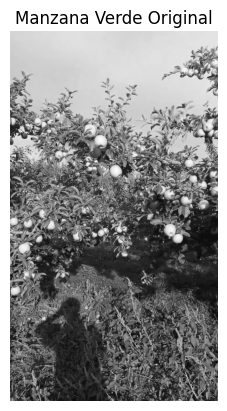

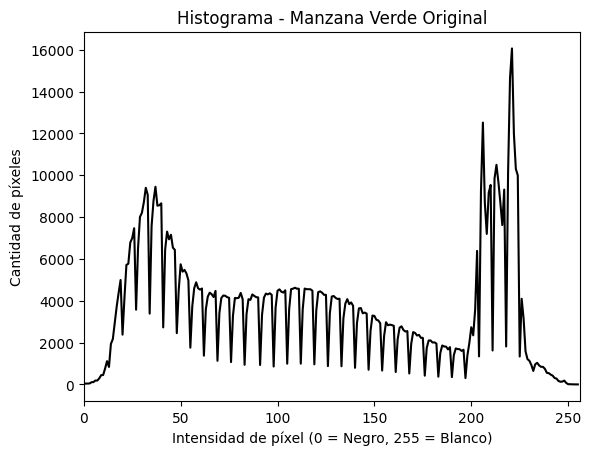

In [58]:
imagen_verde_original_bgr = cv2.imread(r'dataset_manzanas/imagenes/img_001.png')
imagen_verde_original_gris = cv2.cvtColor(imagen_verde_original_bgr, cv2.COLOR_BGR2GRAY)

plt.imshow(imagen_verde_original_gris, cmap='gray')
plt.title("Manzana Verde Original")
plt.axis('off')

histograma_original = plot_histograma(imagen_verde_original_gris, titulo="Histograma - Manzana Verde Original")

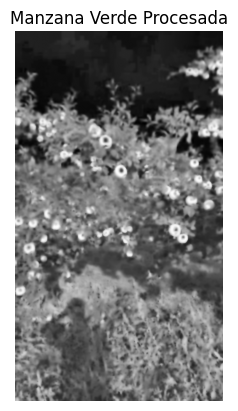

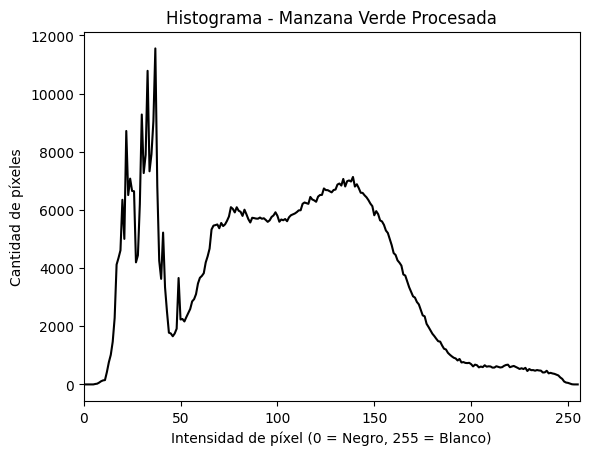

In [59]:
manzana_verde_procesada = preprocesar_canal(imagen_verde_original_bgr, 1)
plt.imshow(manzana_verde_procesada, cmap='gray')
plt.title("Manzana Verde Procesada")
plt.axis('off')

histograma_procesada = plot_histograma(manzana_verde_procesada, titulo="Histograma - Manzana Verde Procesada")

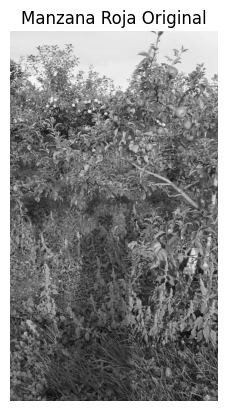

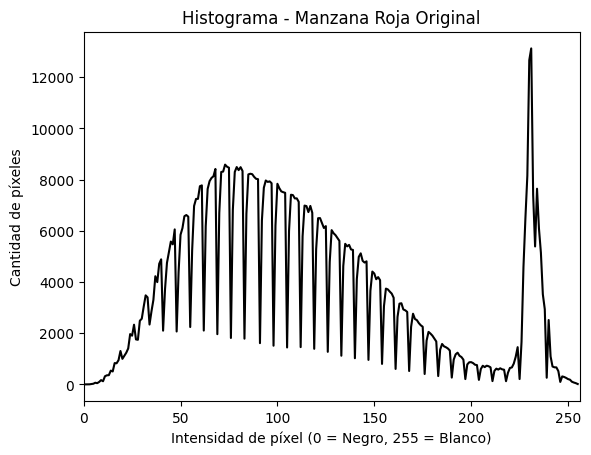

In [61]:
imagen_roja_original_bgr = cv2.imread(r'dataset_manzanas/imagenes/img_094.png')
imagen_roja_original_gris = cv2.cvtColor(imagen_roja_original_bgr, cv2.COLOR_BGR2GRAY)

plt.imshow(imagen_roja_original_gris, cmap='gray')
plt.title("Manzana Roja Original")
plt.axis('off')

histograma_original = plot_histograma(imagen_roja_original_gris, titulo="Histograma - Manzana Roja Original")

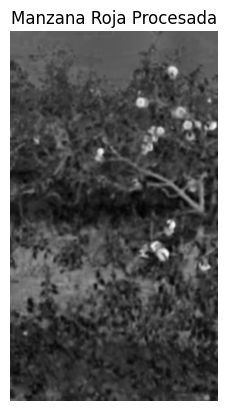

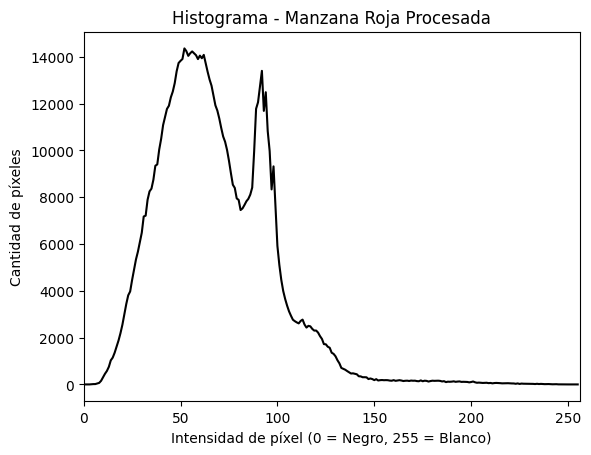

In [62]:
manzana_roja_procesada = preprocesar_canal(imagen_roja_original_bgr, 94)
plt.imshow(manzana_roja_procesada, cmap='gray')
plt.title("Manzana Roja Procesada")
plt.axis('off')

histograma_procesada = plot_histograma(manzana_roja_procesada, titulo="Histograma - Manzana Roja Procesada")

In [63]:
pip install scikit-image

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.9 MB 987.4 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/11.9 MB 987.4 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/11.9 MB 987.4 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/11.9 MB 987.4 kB/s eta 0:00:12
   --- ------------------------------------ 1.0/11.9 MB 606.3 kB/s eta 0:00:18
   ---- ----------------------------------- 1.3/11.9 MB 645.3 kB/s eta 0:00:17
   ---- ----------------------------------- 1.3/11.9 MB 645.3 kB/s eta 0:00:17
   ---- ----------------------------------- 1.3/11.9 MB 645.3 kB/s eta 0:00:17
   ----- ---------------------------------- 1.6/11.9 MB 590.7 kB/s eta 0:00:18
   ----- ---------------------------------- 1.6/11.9 MB 590.7 kB/s eta 0:00:18



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Umbrales Multi-Otsu: [ 49  75 103 149]


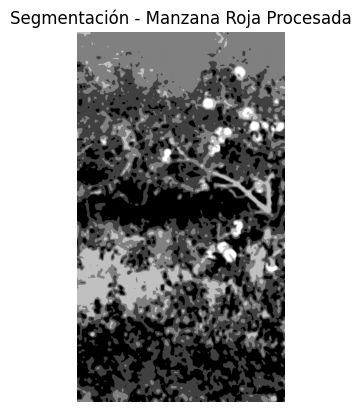

In [67]:
import cv2
import numpy as np
from skimage.filters import threshold_multiotsu

# 1. Cargar imagen en escala de grises con OpenCV

# 2. Aplicar Multi-Otsu (por defecto 3 clases -> devuelve 2 umbrales)
classes = 5
thresholds = threshold_multiotsu(manzana_roja_procesada, classes=classes)

# 3. Usar np.digitize para segmentar la imagen según los umbrales
regions = np.digitize(manzana_roja_procesada, bins=thresholds)

plt.imshow(regions, cmap='gray')
plt.title("Segmentación - Manzana Roja Procesada")
plt.axis('off')

print("Umbrales Multi-Otsu:", thresholds)

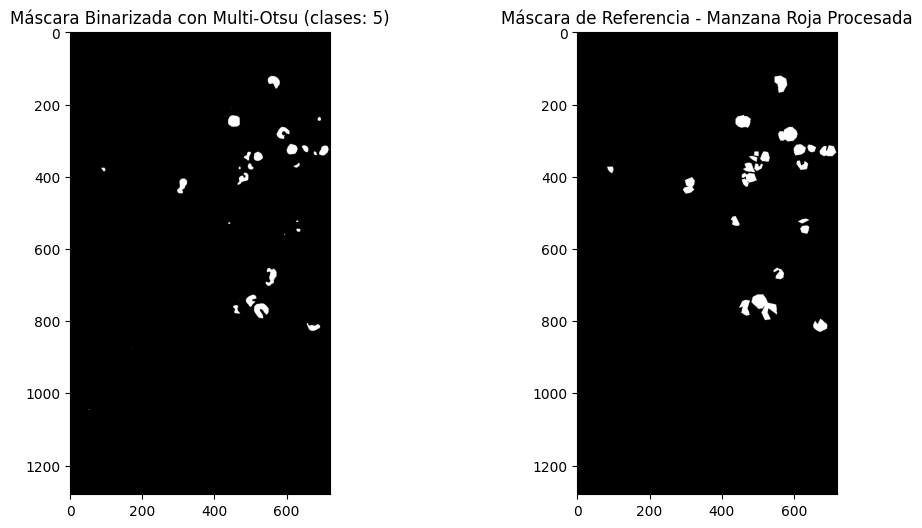

In [78]:
mascara = cv2.threshold(manzana_roja_procesada, thresholds[-1], 255, cv2.THRESH_BINARY)
mascara_ground_truth = cv2.imread(r'dataset_manzanas/mascaras/img_094.png', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(mascara[1], cmap='gray')
plt.title("Máscara Binarizada con Multi-Otsu (clases: 5)")

plt.subplot(1, 2, 2)
plt.imshow(mascara_ground_truth, cmap='gray')
plt.title("Máscara de Referencia - Manzana Roja Procesada")

plt.show()

0
255


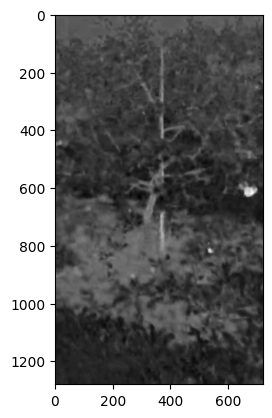

In [12]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(r"..\data\train\preprocessed\img_099.png", cv2.IMREAD_GRAYSCALE)

img_norm = cv2.normalize(img, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
img_uint8 = img_norm.astype(np.uint8)
print(img_uint8.min())

print(img_uint8.max())

plt.imshow(img_uint8, cmap='gray')